# 02 · Engineering drawings harness: better prompting, no training

Baseline: GLM 5.3 Flash with the one-shot schema prompt.

- `glm_fewshot`: three training drawings chosen to cover as many distinct keys as possible
- `glm_fewshot_vote`: same prompt, 5 samples at temperature 0.7, keep the **medoid** (the sample whose fields agree most with the others)

All examples come from the train split; the 60 test drawings stay sealed.

In [1]:
import asyncio, json, os, sys
from pathlib import Path

HERE = Path.cwd()
if not (HERE / "eng_common.py").exists():
    HERE = Path("experiments/eng-drawings-extraction").resolve()
os.chdir(HERE)
sys.path.insert(0, str(HERE))

import eng_common as c
import eng_report as rep
rep.fv.apply_theme()
print({s: len(c.load_split(s)) for s in ("train", "validation", "test")}, "· API key set:", bool(os.getenv("FIREWORKS_API_KEY")))

/opt/homebrew/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 480, 'validation': 60, 'test': 60} · API key set: True


## Pick 3 training drawings that cover the most keys

In [2]:
train = c.load_split("train")
def keys(r):
    return {k for k, _ in c.leaf_pairs(r["gold"])}
picked, covered = [], set()
for _ in range(3):
    best = max((r for r in train if r not in picked), key=lambda r: (len(keys(r) - covered), -len(c.gold_text(r))))
    picked.append(best); covered |= keys(best)
all_keys = set().union(*(keys(r) for r in train))
print(f"3 examples cover {len(covered)} of {len(all_keys)} distinct keys (one-shot example covers {len(keys(train[0]))})")
FEWSHOT = ("You are an expert drawing parser. Extract the drawing as a SINGLE JSON object using EXACTLY the same schema "
           "and key names as these examples. Use only keys that appear in the examples, copy values exactly as printed "
           "on the drawing (keep separators like 60.000 and units like '2 x' only if printed), and omit fields that are "
           "not on the drawing. Respond with ONLY the JSON object, no prose.\n\n"
           + "\n\n".join(f"Example {i+1}:\n{c.gold_text(r)}" for i, r in enumerate(picked)))
print(FEWSHOT[:900], "…")

3 examples cover 17 of 17 distinct keys (one-shot example covers 15)
You are an expert drawing parser. Extract the drawing as a SINGLE JSON object using EXACTLY the same schema and key names as these examples. Use only keys that appear in the examples, copy values exactly as printed on the drawing (keep separators like 60.000 and units like '2 x' only if printed), and omit fields that are not on the drawing. Respond with ONLY the JSON object, no prose.

Example 1:
{"title_block":{"part_number":"PN-5359","material":"A36 Steel","drawn_by":"L. Martinez","date":"10/19/2020","revision":"02","scale":"1:1","title":"SPACER RING","units":"in"},"dimensions":[{"value":15.62,"unit":"in","tolerance":"±0.05"},{"value":17.003,"unit":"in","tolerance":"±0.1"},{"value":8.004,"unit":"in","tolerance":"±0.05"}],"gdt_callouts":[{"type":"runout","value":0.177,"datum":"A"}],"surface_finish":["63 RMS"],"treatment":"Zinc Plated","weld_symbols":[{"type":"groove"}],"notes":["BREAK A …


## Run · ≈$0.15 few-shot, ≈$0.75 with 5 samples

In [3]:
await c.eval_model("glm", "glm_fewshot", system=FEWSHOT)
await c.eval_model("glm", "glm_fewshot_vote", system=FEWSHOT, n=5, temperature=0.7)

glm_fewshot: GLM 5.3 Flash on test · n=1 · to_run=0
glm_fewshot: mean JSON F1 88.2% · valid JSON 60/60
glm_fewshot_vote: GLM 5.3 Flash on test · n=5 · to_run=0
glm_fewshot_vote: mean JSON F1 88.3% · valid JSON 60/60


## Results vs the one-shot baseline

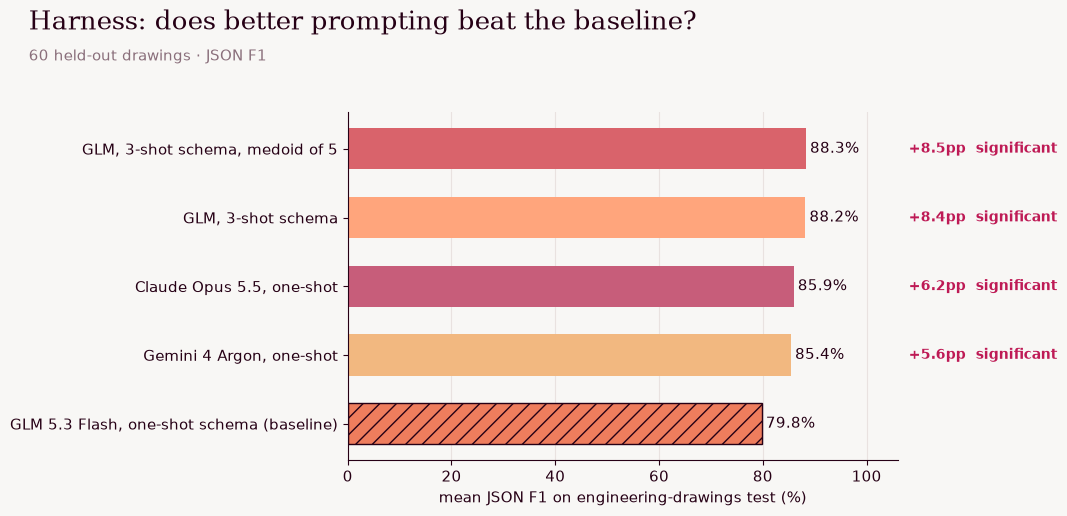

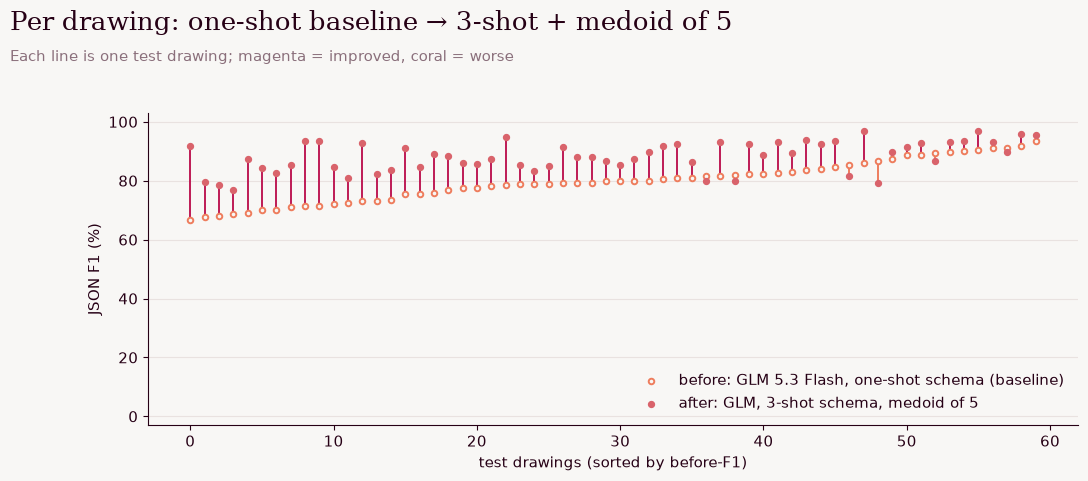

In [4]:
rep.leaderboard(["glm_oneshot", "glm_fewshot", "glm_fewshot_vote", "gemini4_oneshot", "opus55_oneshot"], "glm_oneshot",
                "Harness: does better prompting beat the baseline?", "60 held-out drawings · JSON F1")
rep.before_after("glm_oneshot", "glm_fewshot_vote", "Per drawing: one-shot baseline → 3-shot + medoid of 5",
                 "Each line is one test drawing; magenta = improved, coral = worse")

In [5]:
rep.significance_table([("glm_fewshot", "glm_oneshot"), ("glm_fewshot_vote", "glm_oneshot")])

,drawings,fields,F1 a,F1 b,ΔF1 pp,fields only a,fields only b,McNemar p (fields),bootstrap 95% CI (drawings),significant,notes
pair,,,,,,,,,,,
"GLM, 3-shot schema vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,88.2%,79.8%,8.4,206,26,6.10e-36,"[+6.7, +10.0]",True,GAIN holds under both tests
"GLM, 3-shot schema, medoid of 5 vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,88.3%,79.8%,8.5,208,28,3.57e-35,"[+6.9, +10.1]",True,GAIN holds under both tests


,drawings,fields,F1 a,F1 b,ΔF1 pp,fields only a,fields only b,McNemar p (fields),bootstrap 95% CI (drawings),significant,notes
pair,,,,,,,,,,,
"GLM, 3-shot schema vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,88.2%,79.8%,8.4,206,26,6.10e-36,"[+6.7, +10.0]",True,GAIN holds under both tests
"GLM, 3-shot schema, medoid of 5 vs GLM 5.3 Flash, one-shot schema (baseline)",60,1791,88.3%,79.8%,8.5,208,28,3.57e-35,"[+6.9, +10.1]",True,GAIN holds under both tests


**Stats.** Field-level McNemar: each of the 2,163 gold fields in the 60 test drawings is right or wrong for each system. Drawing-level bootstrap on mean F1 (resampling drawings). A gain counts only when both are significant.